11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step 
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 14s 0us/step
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 728s 860ms/step - accuracy: 0.8804 - loss: 0.5179 - val_accuracy: 0.9335 - val_loss: 0.2335
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 527s 625ms/step - accuracy: 0.9314 - loss: 0.2285 - val_accuracy: 0.9485 - val_loss: 0.1771
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 635s 753ms/step - accuracy: 0.9432 - loss: 0.1770 - val_accuracy: 0.9453 - val_loss: 0.1672
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 540s 640ms/step - accuracy: 0.9502 - loss: 0.1511 - val_accuracy: 0.9495 - val_loss: 0.1528
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 483s 572ms/step - accuracy: 0.9549 - loss: 0.1392 - val_accuracy: 0.9572 - val_loss: 0.1487
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 314s 367ms/step - accuracy: 0.9074 - loss: 0.3794 - val_accuracy: 0.9743 - val_loss: 0.0824
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 247s 293ms/step - accuracy: 0.9751 - loss: 0.0797 - val_accuracy: 0.980

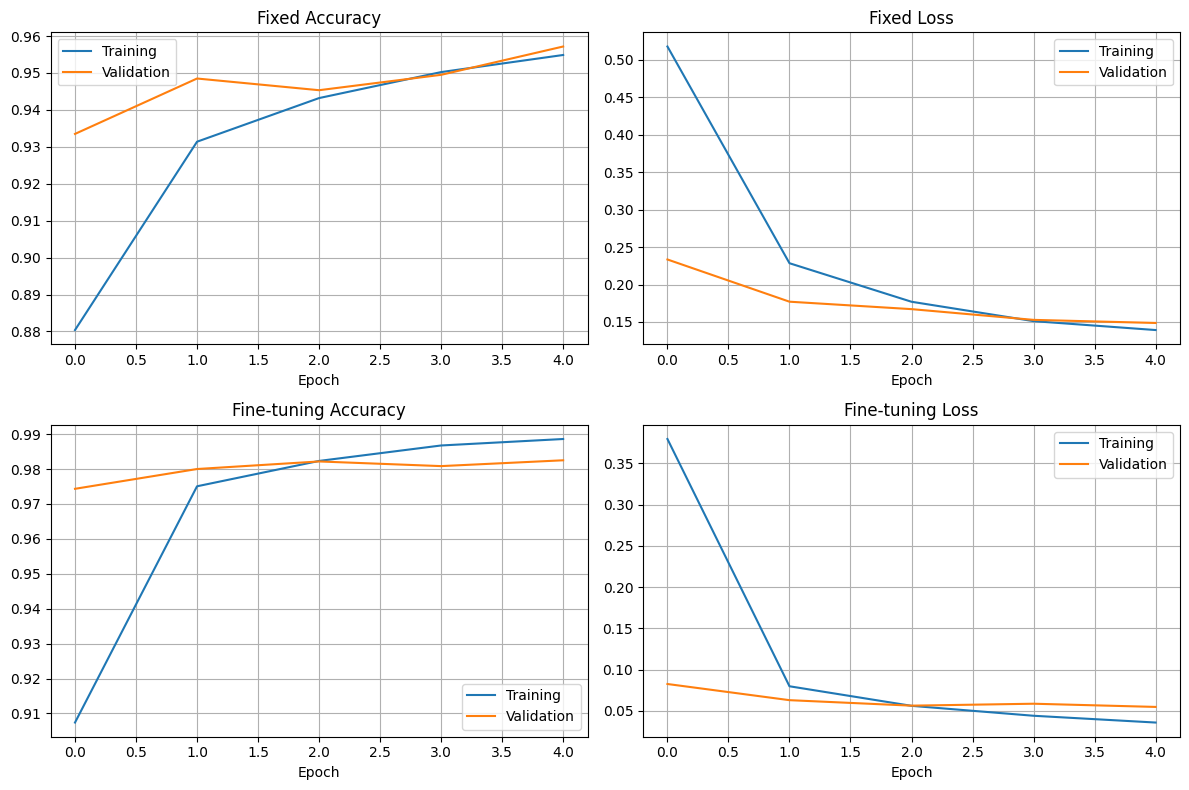

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model
from tensorflow.keras.datasets import mnist
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.utils import to_categorical

# Load dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Preprocessing
x_train = tf.image.grayscale_to_rgb(tf.image.resize(x_train[..., None], (32, 32))).numpy()
x_test = tf.image.grayscale_to_rgb(tf.image.resize(x_test[..., None], (32, 32))).numpy()

x_train = preprocess_input(x_train)
x_test = preprocess_input(x_test)
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Create VGG19 model
def create_model():
    base = VGG19(weights="imagenet", include_top=False,
                 input_shape=(32, 32, 3))
    base.trainable = False

    x = layers.Flatten()(base.output)
    x = layers.Dense(512, activation="relu")(x)
    output = layers.Dense(10, activation="softmax")(x)

    return base, Model(base.input, output)

# Fixed feature extraction
base, model = create_model()
model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

h1 = model.fit(x_train, y_train, epochs=5,
               batch_size=64, validation_split=0.1)
loss1, acc1 = model.evaluate(x_test, y_test, verbose=0)

# Fine-tuning
base, model_ft = create_model()
base.trainable = True

for layer in base.layers[:-4]:
    layer.trainable = False

model_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

h2 = model_ft.fit(x_train, y_train, epochs=5,
                  batch_size=64, validation_split=0.1)
loss2, acc2 = model_ft.evaluate(x_test, y_test, verbose=0)

# Results
print("Fixed Accuracy:", acc1 * 100, "%")
print("Fine-tuning Accuracy:", acc2 * 100, "%")
print("Fixed Loss:", loss1)
print("Fine-tuning Loss:", loss2)

# Plot accuracy and loss
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

for a, h, title in [
    (ax[0,0], h1, "Fixed Accuracy"),
    (ax[0,1], h1, "Fixed Loss"),
    (ax[1,0], h2, "Fine-tuning Accuracy"),
    (ax[1,1], h2, "Fine-tuning Loss")
]:
    key = "accuracy" if "Accuracy" in title else "loss"
    a.plot(h.history[key], label="Training")
    a.plot(h.history["val_" + key], label="Validation")
    a.set_title(title)
    a.set_xlabel("Epoch")
    a.legend()
    a.grid()

plt.tight_layout()
plt.show()
